# S01 — Introducción práctica a ML con Iris
**Objetivo:** ver el flujo básico de ML en minutos: cargar datos, explorarlos, entrenar un modelo simple y evaluar.

**Flujo:** Datos → EDA → Partición → Modelo → Predicción → Evaluación


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (6,4)

## 1) Cargar y entender el dataset
- Usaremos **Iris**, un dataset clásico con 150 flores y 4 medidas (largo/ancho de sépalos y pétalos).
- La **variable objetivo** es la especie: *setosa*, *versicolor*, *virginica*.
- Convertimos a **DataFrame** para inspeccionar filas, columnas y tipos de datos.

In [3]:

iris = load_iris()
X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df["target"] = y
df["species"] = df["target"].map({i:name for i, name in enumerate(iris.target_names)})

df.head()



,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 2) Dimensiones, tipos, nulos y estadísticas
- **shape**: cuántas filas/columnas hay.
- **info()**: tipos de datos y memoria.
- **isna().sum()**: verificar **missing**.
- **describe()**: estadísticas (media, desviación, percentiles).

In [4]:
print("Dimensiones:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)

print("\nValores faltantes por columna:")
print(df.isna().sum())

print("\nResumen estadístico (numérico):")
df.describe()

Dimensiones: (150, 6)

Tipos de datos:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species               object
dtype: object

Valores faltantes por columna:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Resumen estadístico (numérico):


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


## 3) Distribución de la variable objetivo
- Ver cuántos ejemplos hay por especie.
- Un **barplot** ayuda a visualizar clases balanceadas o no.

C:\Users\Rafael\AppData\Local\Temp\ipykernel_30812\2936399993.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="species", data=df, palette="Set2")


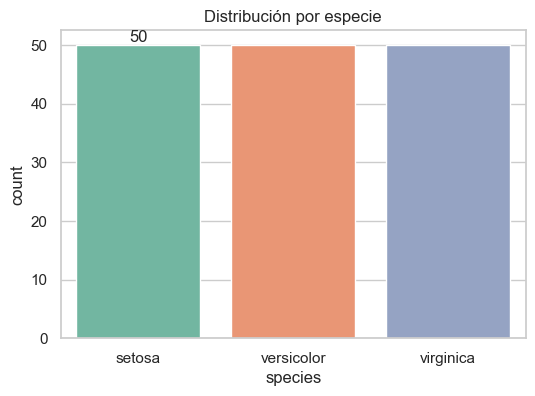

In [5]:
ax = sns.countplot(x="species", data=df, palette="Set2")
ax.bar_label(ax.containers[0])
plt.title("Distribución por especie")
plt.show()


## 4) EDA mínimo: relaciones entre variables
- Un gráfico 2D simple (p. ej., **petal length vs petal width**) suele separar bien las especies.
- Objetivo: **intuir** qué variables discriminan mejor.

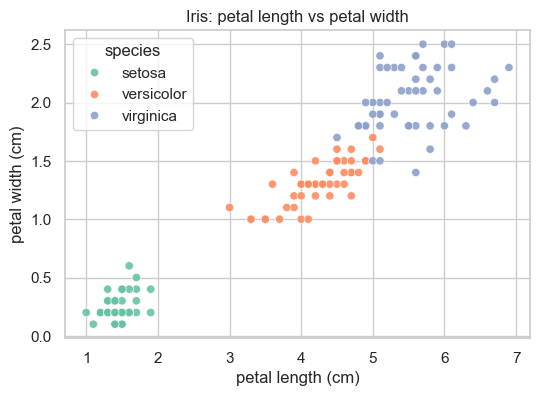

In [11]:
sns.scatterplot(
    data=df,
    x="petal length (cm)", y="petal width (cm)",
    hue="species", palette="Set2", alpha=0.9
)
plt.title("Iris: petal length vs petal width")
plt.show()

## 5) Partición de datos (train/test)
- Separar datos de **entrenamiento** y **prueba** permite evaluar generalización.
- `test_size=0.3` → 70% train / 30% test.
- `stratify=y` mantiene proporción de clases.

In [6]:
X = df[iris.feature_names].values
y = df["target"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_train.shape, X_test.shape


((105, 4), (45, 4))

## 6) Modelo base: Árbol de Decisión
- Modelo **intuitivo** y **rápido** para una primera prueba.
- Pasos: **instanciar → entrenar → predecir → evaluar**.

In [7]:
dt = DecisionTreeClassifier(random_state=42, max_depth=3)  # max_depth para hacerlo legible
dt.fit(X_train, y_train)

y_pred = dt.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print(f"Precisión (accuracy) en test: {acc:.3f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Precisión (accuracy) en test: 0.978

Reporte de clasificación:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.93      0.97        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.98        45
   macro avg       0.98      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45



## 7) Matriz de confusión
- Filas: **clase real**. Columnas: **predicción**.
- Muestra **aciertos** (diagonal) y **errores** (fuera de la diagonal).

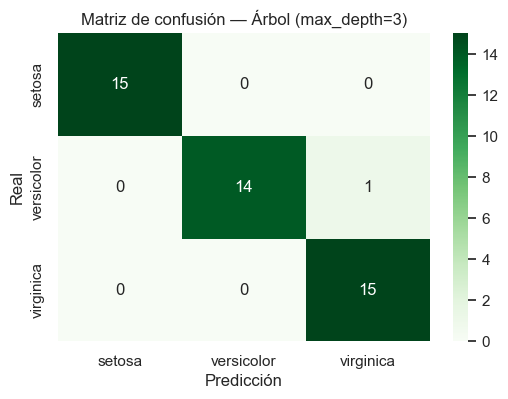

In [8]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=iris.target_names,
            yticklabels=iris.target_names)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión — Árbol (max_depth=3)")
plt.show()

## 8) (Opcional) Visualizar el árbol
- Útil para **explicar reglas**: qué variable se evalúa en cada nodo y con qué umbral.
- Ideal para **storytelling** con áreas de decisión sencillas.

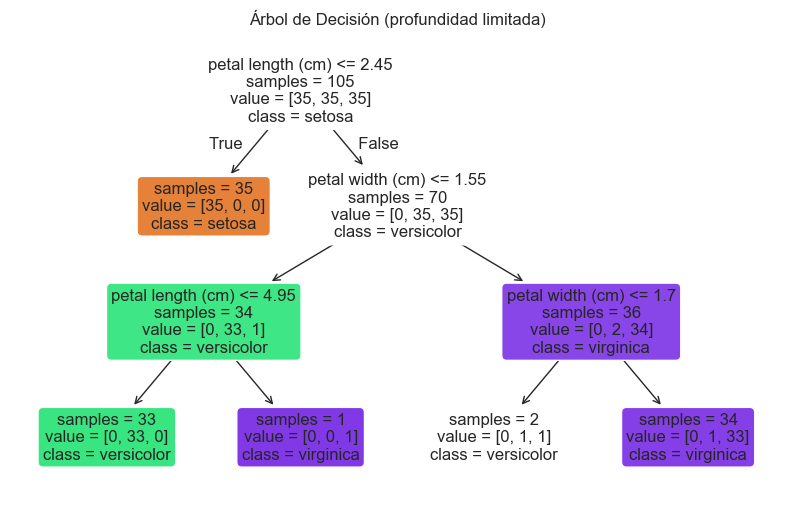

In [9]:
plt.figure(figsize=(10,6))
plot_tree(
    dt, feature_names=iris.feature_names, class_names=iris.target_names,
    filled=True, rounded=True, impurity=False
)
plt.title("Árbol de Decisión (profundidad limitada)")
plt.show()

## 9) Predicción de ejemplo
- Tomamos una observación de prueba y mostramos:
  - **Entrada** (medidas)
  - **Especie real vs predicha**
  - **Probabilidades** por clase

In [10]:
i = 0  # prueba con otros índices 0..len(X_test)-1
ejemplo = X_test[i].reshape(1, -1)
pred = dt.predict(ejemplo)[0]
proba = dt.predict_proba(ejemplo)[0]

print("Medidas:", dict(zip(iris.feature_names, X_test[i])))
print("Real:", iris.target_names[y_test[i]])
print("Predicha:", iris.target_names[pred])
print("Probabilidades:", {iris.target_names[j]: round(proba[j], 3) for j in range(len(proba))})

Medidas: {'sepal length (cm)': np.float64(7.3), 'sepal width (cm)': np.float64(2.9), 'petal length (cm)': np.float64(6.3), 'petal width (cm)': np.float64(1.8)}
Real: virginica
Predicha: virginica
Probabilidades: {np.str_('setosa'): np.float64(0.0), np.str_('versicolor'): np.float64(0.029), np.str_('virginica'): np.float64(0.971)}


## Cierre y siguientes pasos
- Flujo básico visto: **EDA breve → modelo base → evaluación**.
- En próximas sesiones:
  - Mejorar EDA (más visualizaciones).
  - Comparar otros modelos (k‑NN, SVM, regresión logística).
  - Validación cruzada e hiperparámetros.